## Домашнее задание № 1 (Макс. 10 баллов)

В данной домашней работе мы познакомимся на практике с пройденными темами, включающими в себя статистику, проверку гипотез и A/B тестирование.

### Задача 1 (2 балла)

**(1 Балл)** Рассчитайте среднее, стандартное отклонение и медиану по 1000 случайных выборок, порождённых нормальным распределением с $\mu = 5$ и $\sigma^2 = 4$, состоящих из 100 элементов. Постройте распределение полученных метрик.

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as sps
from tqdm import tqdm

def calc_stat_random_sample(mu=5, sigma=4, size=100):
    ... # Место для вашего кода
    sample = sps.norm(loc=mu, scale=sigma ** 0.5).rvs(size=size)
    return(np.mean(sample), np.std(sample), np.median(sample))

n_samples = 1000

... # Место для вашего кода
mean_arr = []
std_arr = []
med_arr = []

for i in tqdm(range(1000)):
    m, s, med = calc_stat_random_sample()
    mean_arr.append(m)
    std_arr.append(s) 
    med_arr.append(med)

100%|██████████| 1000/1000 [00:01<00:00, 850.49it/s]


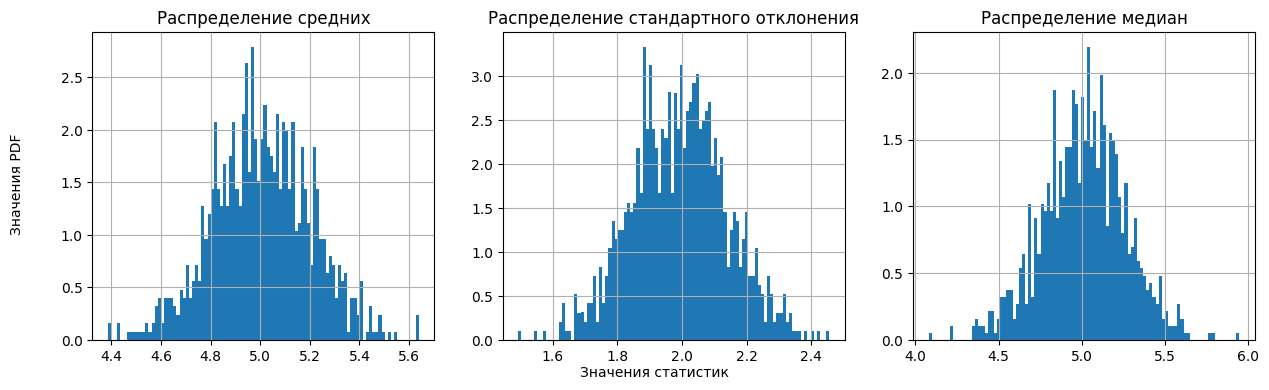

In [13]:
fig, axs = plt.subplots(1, 3, figsize = (15, 4))

axs[0].hist(mean_arr, bins = 100, density = True)
axs[1].hist(std_arr, bins = 100, density = True)
axs[2].hist(med_arr, bins = 100, density = True)


axs[0].set_title("Распределение средних")
axs[1].set_title("Распределение стандартного отклонения")
axs[2].set_title('Распределение медиан')

for ax in axs:
    ax.grid()

fig.supxlabel('Значения статистик', fontsize = 10)
fig.supylabel('Значения PDF', x = 0.07, fontsize = 10)
plt.show()

**(1 Балл)** Какому распределению принадлежит распределение средних? Почему?

Пусть у нас есть тысяча выборок вида $(X_1^{(i)}, \dots, X_{100}^{(i)}), \ i \in \{1, \dots, 1000\}$, $X_i^{(j)} \sim N(5, 4)$, причем они независимы.

Мы собираем с них статистику в виде среднего значения, то есть:
$$
S_i := \frac{1}{100}\sum_{j=1}^{100} X_j^{(i)}
$$
Теперь нам хотелось бы узнать распределение этих случайных величин, так как они независимы, то в бой вступают характеристические функции:
$$
\phi_{S_i}(t) = \phi_{\frac{1}{100} X_1^{(i)}}(t) \cdot \dots \cdot \phi_{\frac{1}{100} X_{100}^{(i)}}(t) =^{\text{iid}} 
$$
Мы знаем, что умножение на константу нормальной случайной величины оставляет её распределение, но меняет её параметры, то есть $\frac{1}{100} X_1^{(i)} \sim N(0.05, 0.0004)$
$$
=^{\text{iid}} (e^{0.05it - 0.0002t^2})^{100} = e^{5it - 0.02t^2}
$$
А тогда, раз её характеристическая функция имеет такой вид, то $S_i \sim N(5, 0.04)$. Это теоретическое обоснование подтверждает и график, так как наибольшее количество измерений сконцентрировано около 5, а стандартное отклонение действительно составляет $\sqrt{0.04}= 0.2$, так как почти все измерения укладываются в отрезок $[4.4, 5.6]$

### Задача 2 (2 балла):

Оцените значение $\hat{\mu}$ параметра $\mu$ **(1 балл)** для нормального распределения $\mathscr{N}(\mu,1)$ используя метод максимального правдоподобия.

Справка: функция плотности распределения для нормального распределения имеет вид:
$$
    f(x) = \frac{1}{\sqrt{2 \pi \sigma^2}} \text{e}^{-\frac{(x - \mu)^2}{2 \sigma^2}}
$$

Функция правдоподобия 

Её логарифм: 

Дифференцируем: 

Ищем экстремум: , откуда

Сгенерируйте 1000 выборок размером 1000 наблюдений из нормального распределения с $\mu = 5, \sigma^2 = 1$, постройте распределение разности $\mu - \hat{\mu}$ и найдите среднее этой разности в зависимости от числа выборок **(1 балл)**.

In [8]:
# Место для вашего кода и картинок

### Задача 3 (2 балла)

**(1 балл)** Пусть известно, что выборка в n наблюдений порождена распределением Бернулли ~Bernoulli(p), пусть среднее значение по выборке равно $\hat{p}$. Постройте формулу 95% доверительного интервал для среднего

**(1 балл)** Постройте 95% доверительный интервал на среднее в представленной выборке, используя бутстрап и сравните с теоретическим значением

In [14]:
X = sps.bernoulli.rvs(0.2, size = 10000, random_state=42)

...

Ellipsis

### Задача 4 (4 балла)

Основным критерием для тестирования гипотезы о равенстве средних является t-test. Он строится на том, что по ЦПТ практически для любой случайной величины средние будут распределены нормально. 

В учебниках по статистике доказывается, что в силу этого для двух выборок, порождённых одинаково распределёнными независимыми случайными величинами с равным средним мы имеем асимпототику для выборочной t-статистики
$$
    T = \frac{\bar{x} - \bar{y}}{\sqrt{\frac{s_x^2}{n_1} + \frac{s_y^2}{n_2}}} \rightarrow t_{n_1 + n_2 - 2},
$$
где $\bar{x}, \bar{y}$ -- выборочные средние в выборках, $s_x^2, s_y^2$ -- выборочные дисперсии, $n_1, n_2$ -- размеры выборок, а $t_{n_1 + n_2 - 2}$ -- распределение Стьюдента с $n_1 + n_2 - 2$ степенями свободы.

**(1 балл)** Постройте плотность распределения Стьюдента с 1, 5, 10, 100 и 1000 степеней свободы, а также плотность стандартного нормального распределения

In [18]:
grid = np.arange(-10,10,0.01)

freedom_degrees = [1,5,10,100,1000]

# Место для вашего кода и картинок

**(1 балл)** Пусть нам необходимо запустить A/B тест: в первой группе мы оставляем кнопку в банковском приложении в сером цвете, во втором -- красим её в жёлтый. Всего у нас в месяц в приложение заходит 1000 различных клиентов. Базовая конверсия в нажатие кнопки сейчас составляет 0.2. Бизнес постановил, что MDE = 5%, то есть значимым будет считаться изменение, при котором конверсия будет больше 0.21 или меньше 0.19. Хватит ли нам данных, чтобы замерить эффект за один месяц при уровне значимости $\alpha = 0.05$, если мы планируем поделить выборку пополам на тест и контроль?

In [21]:
# Место для вашего кода

**(1 балл)** Мы провели тест и получили следующие результаты:

In [24]:
X_1, X_2 = sps.bernoulli.rvs(0.2, size = 1000, random_state=42), sps.bernoulli.rvs(0.21, size = 1000, random_state=42)

Можем ли мы утверждать на уровне значимости $\alpha = 0.05$, что эффект имел место быть?

In [27]:
# Место для вашего кода

**(1 балл)** 

Что будет, если мы проведём 1000 таких тестов, "отпустив" random_state?

В какой доле случаев мы не задетектируем это существующее различие? Чему будет равна $\beta$?

In [30]:
# Под "отпущенным" random_state понимается None
# X_1, X_2 = sps.bernoulli.rvs(0.2, size = 1000), sps.bernoulli.rvs(0.21, size = 1000)

# Место для кода

А если различий не будет (при проведении 1000 A/A-тестов)? Как будет распределено p-value в этом случае?

In [33]:
# Под A/A тестом имеем в виду: X_1, X_2 = sps.bernoulli.rvs(0.2, size = 1000), sps.bernoulli.rvs(0.2, size = 1000)

# Место для кода